# Predicción del rendimiento FP32 en GPUs

El objetivo de este proyecto es predecir si una GPU es "de bajo, medio o alto rendimiento"

## 0. Librerias

In [85]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import userdata
from sklearn.experimental import enable_iterative_imputer  # habilita el imputador
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score, f1_score
from sklearn.impute import IterativeImputer

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

## 1. Carga de datos

### CSV desde kaggle

In [86]:
# 1. Configurar la clave API de Kaggle
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
!kaggle datasets download -d psychocoderxd/gpu-performance-prediction

# 2. Descargar y descomprimir el dataset directamente desde Kaggle
!kaggle datasets download -d psychocoderxd/gpu-performance-prediction
!unzip -o gpu-performance-prediction.zip

# 3. Cargar el dataset (unificando train/test si aplica)
df = pd.read_csv("train.csv") # o "test.csv" según corresponda

Dataset URL: https://www.kaggle.com/datasets/psychocoderxd/gpu-performance-prediction
License(s): CC-BY-NC-SA-4.0
gpu-performance-prediction.zip: Skipping, found more recently modified local copy (use --force to force download)
Dataset URL: https://www.kaggle.com/datasets/psychocoderxd/gpu-performance-prediction
License(s): CC-BY-NC-SA-4.0
gpu-performance-prediction.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  gpu-performance-prediction.zip
  inflating: test.csv                
  inflating: train.csv               


### carga y exploracion inicial

In [87]:
pd.read_csv("train.csv")

print(df.shape)

df.info()

df.head()

(10000, 19)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                10000 non-null  int64  
 1   cores             9993 non-null   float64
 2   tensor_cores      3625 non-null   float64
 3   rt_cores          4221 non-null   float64
 4   sm_count          6003 non-null   float64
 5   base_clock        7976 non-null   float64
 6   boost_clock       7976 non-null   float64
 7   memory_clock      10000 non-null  float64
 8   ram               10000 non-null  float64
 9   bus_width         10000 non-null  float64
 10  fp16_performance  6725 non-null   float64
 11  fp32_performance  9993 non-null   float64
 12  fp64_performance  9374 non-null   float64
 13  bf16_performance  6 non-null      float64
 14  tf32_performance  6 non-null      float64
 15  int8_performance  0 non-null      float64
 16  multi_gpu         0 non-null 

,id,cores,tensor_cores,rt_cores,sm_count,base_clock,boost_clock,memory_clock,ram,bus_width,fp16_performance,fp32_performance,fp64_performance,bf16_performance,tf32_performance,int8_performance,multi_gpu,api_cuda,gpi_value
0,1748,6144.000,192.000,48.000,48.000,1575.000,1815.000,1188.000,8.000,256.000,22.300,22.300,0.348,NaN,NaN,NaN,NaN,8.600,11.480
1,13263,1920.000,240.000,30.000,30.000,600.000,1215.000,1500.000,6.000,192.000,9.331,4.666,0.146,NaN,NaN,NaN,NaN,7.500,3.890
2,1526,4864.000,152.000,38.000,38.000,1410.000,1680.000,1750.000,8.000,256.000,16.340,16.340,0.255,NaN,NaN,NaN,NaN,8.600,9.100
3,1862,336.000,NaN,NaN,7.000,NaN,NaN,850.000,1024.000,256.000,NaN,0.874,0.073,NaN,NaN,NaN,NaN,2.100,2.840
4,7001,3072.000,384.000,48.000,48.000,1650.000,1860.000,1937.000,8.000,256.000,22.860,11.430,0.357,NaN,NaN,NaN,NaN,7.500,7.630


## 2. Diccionario de Variables


1. Identificador de la Fila
    * id: Es el identificador o número de fila de la tarjeta de video.

2. Especificaciones Técnicas y de Arquitectura
Son métricas cuantitativas sobre los componentes físicos de la GPU:

    * cores: Cantidad de núcleos principales de procesamiento (por ejemplo, núcleos CUDA o Stream Processors).

    * tensor_cores: Número de núcleos dedicados a cálculos de Inteligencia Artificial y Deep Learning.

    * rt_cores: Número de núcleos dedicados a trazado de rayos (Ray Tracing en tiempo real).

    * sm_count: Cantidad de Streaming Multiprocessors (bloques de procesamiento general de la arquitectura).

    * base_clock: Velocidad base de reloj del procesador de la GPU (en MHz).

    * boost_clock: Velocidad máxima o con turbo (boost) a la que puede operar el procesador (en MHz).

    * memory_clock: Velocidad o frecuencia de transferencia de la memoria VRAM (en MHz).

    * ram: Capacidad total de memoria VRAM (normalmente en GB).

    * bus_width: Ancho de banda del bus de memoria (medido en bits, ej: 128-bit, 256-bit, 384-bit).

3. Rendimiento en Operaciones Matemáticas (Métricas de Cómputo)
Variables que miden la potencia bruta de la tarjeta en distintas precisiones:

    * fp16_performance: Potencia en media precisión (16 bits) en TFLOPS.

    * fp32_performance: Potencia en precisión simple (32 bits) en TFLOPS. Esta es la Variable Objetivo (Target) a predecir.

    * fp64_performance: Potencia en doble precisión (64 bits) en TFLOPS (usada en cómputo científico).

4. Columnas Vacías (Sin Datos / 100% NaN):

    * bf16_performance: Potencia en Bfloat16. (Completamente vacía).

    * tf32_performance: Potencia en TensorFloat-32. (Completamente vacía).

    * int8_performance: Rendimiento en enteros de 8 bits. (Completamente vacía).

    * multi_gpu: Métrica de soporte multitarjeta. (Completamente vacía).

5. Software y Evaluación Comercial
    * api_cuda: Versión o nivel de compatibilidad con la API de cómputo CUDA de Nvidia.

    * gpi_value: Un índice o puntuación ponderada de rendimiento global del chip (GPU Performance Index).

## 3. Análisis exploratorio (EDA)

### Tipos de variables

In [88]:
# esto es por cumplpir lo que dice el pdf
# separamos las numericas y las categoricas
# igual como podemos ver en el dataset sabemos que todas van a ser numericas xd
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
print(f"Variables Numéricas ({len(numeric_cols)}): {numeric_cols}")

categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()
print(f"Variables Categóricas ({len(categorical_cols)}): {categorical_cols}")

Variables Numéricas (19): ['id', 'cores', 'tensor_cores', 'rt_cores', 'sm_count', 'base_clock', 'boost_clock', 'memory_clock', 'ram', 'bus_width', 'fp16_performance', 'fp32_performance', 'fp64_performance', 'bf16_performance', 'tf32_performance', 'int8_performance', 'multi_gpu', 'api_cuda', 'gpi_value']
Variables Categóricas (0): []


### Reporte de valores nulos

In [89]:
# Definición la variable objetivo (Target)
TARGET = "fp32_performance"
print(f"Variable Objetivo definida: {TARGET}")

# Reporte de datos nulos por columna

# hacemos el null_report con dos columnas por cada categoria, una de valores
# nulos donde es la suma de estos y otro que seria el porcentaje pa visajear
null_report = pd.DataFrame({  # usamos df porque sabemos que todos son numericos
    "Valores Nulos": df.isnull().sum(),
    "Porcentaje (%)": (df.isnull().sum() / len(df)) * 100
}).sort_values(by="Porcentaje (%)", ascending=False)

display(null_report)

Variable Objetivo definida: fp32_performance


,Valores Nulos,Porcentaje (%)
int8_performance,10000,100.000
multi_gpu,10000,100.000
bf16_performance,9994,99.940
tf32_performance,9994,99.940
tensor_cores,6375,63.750
rt_cores,5779,57.790
sm_count,3997,39.970
fp16_performance,3275,32.750
api_cuda,2700,27.000
base_clock,2024,20.240


### Distribucion de columnas con nulos


Lote 1: ['cores', 'tensor_cores', 'rt_cores', 'sm_count']


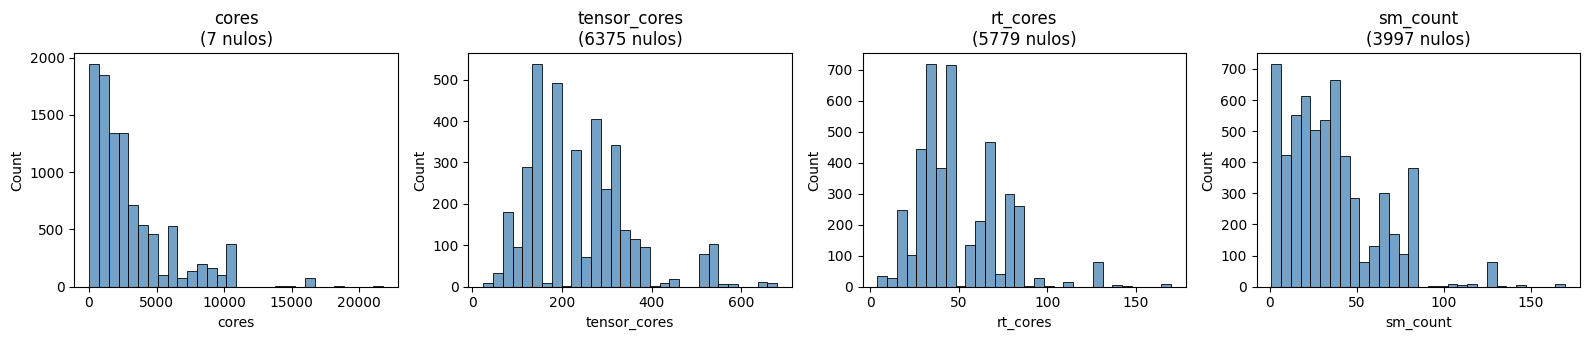

Lote 2: ['base_clock', 'boost_clock', 'fp16_performance', 'fp64_performance']


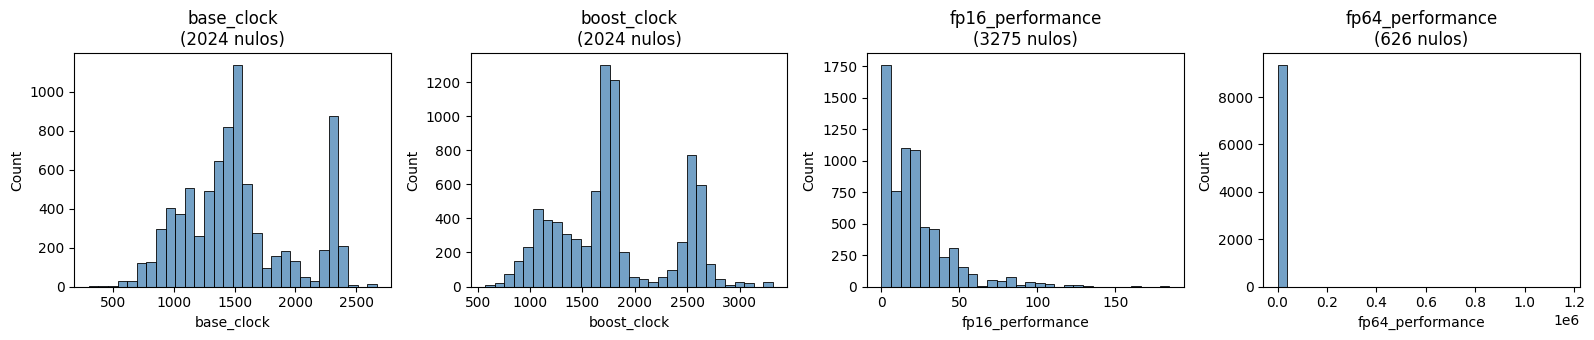

Lote 3: ['bf16_performance', 'tf32_performance', 'int8_performance', 'multi_gpu']


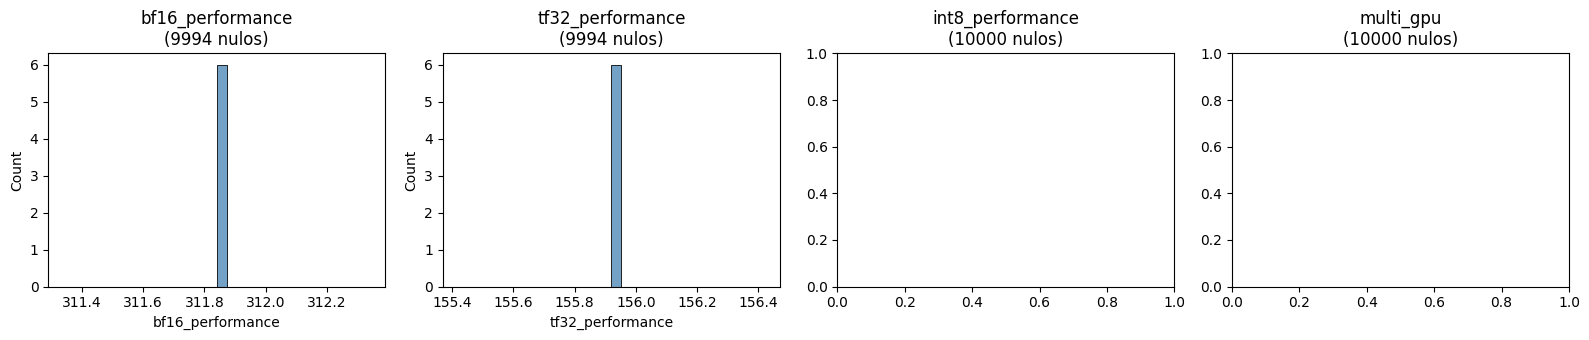

Lote 4: ['api_cuda']


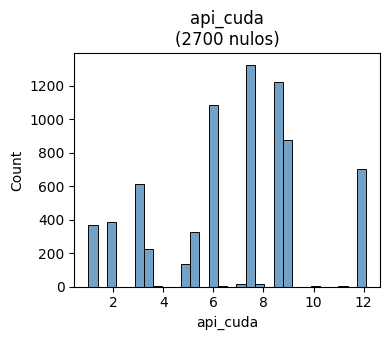

In [90]:
# Visualización de la distribucion de cada columna

# hacemos una lista con las columnas que contengan nulo excepto el id, el gpi_value y pues el target
cols_nulos = [
    c for c in df.columns
    if df[c].isnull().sum() > 0 and c not in ["id", "gpi_value", TARGET]
]

# crea y muestra gráficos de distribución (histogramas) para las columnas con
# valores nulos, organizándolos en grupos (lotes) de máximo 4 gráficos por fila.
for i in range(0, len(cols_nulos), 4):
    lote = cols_nulos[i:i+4]
    print(f"Lote {i//4 + 1}: {lote}")

    fig, axes = plt.subplots(1, len(lote), figsize=(4 * len(lote), 3.5))
    if len(lote) == 1:
        axes = [axes]

    for ax, col in zip(axes, lote):
        sns.histplot(df[col].dropna(), bins=30, kde=False,
                     ax=ax, color="steelblue")
        ax.set_title(f"{col}\n({df[col].isnull().sum()} nulos)")

    plt.tight_layout()
    plt.show()

## 4. Limpieza de datos

### Eliminación de columnas vacías

In [91]:
# eliminamos las columnas que no aportan nada porque estan vacias o practicamente sin elementos
cols_a_eliminar = ["bf16_performance", "tf32_performance", "int8_performance", "multi_gpu"]
df = df.drop(columns=[c for c in cols_a_eliminar if c in df.columns])
print("Nuevas dimesiones:", df.shape)
df.head()

Nuevas dimesiones: (10000, 15)


,id,cores,tensor_cores,rt_cores,sm_count,base_clock,boost_clock,memory_clock,ram,bus_width,fp16_performance,fp32_performance,fp64_performance,api_cuda,gpi_value
0,1748,6144.000,192.000,48.000,48.000,1575.000,1815.000,1188.000,8.000,256.000,22.300,22.300,0.348,8.600,11.480
1,13263,1920.000,240.000,30.000,30.000,600.000,1215.000,1500.000,6.000,192.000,9.331,4.666,0.146,7.500,3.890
2,1526,4864.000,152.000,38.000,38.000,1410.000,1680.000,1750.000,8.000,256.000,16.340,16.340,0.255,8.600,9.100
3,1862,336.000,NaN,NaN,7.000,NaN,NaN,850.000,1024.000,256.000,NaN,0.874,0.073,2.100,2.840
4,7001,3072.000,384.000,48.000,48.000,1650.000,1860.000,1937.000,8.000,256.000,22.860,11.430,0.357,7.500,7.630


### Eliminación de filas con target nulo

El target `fp32_performance` **nunca se imputa**: es la variable que el modelo
debe aprender a predecir. Si inventamos sus valores con imputación, estaríamos
entrenando al modelo con datos falsos.

Por eso, las 7 filas que tienen `fp32_performance` nulo se **eliminan**
directamente del dataset.

In [92]:
n_antes = len(df)
df = df.dropna(subset=[TARGET]).reset_index(drop=True)
print(f"Filas eliminadas por target nulo: {n_antes - len(df)}")
print(f"Nuevo shape: {df.shape}")

Filas eliminadas por target nulo: 7
Nuevo shape: (9993, 15)


### Imputación multivariada

In [93]:
# basicamente vamos a llenar los espacios que estan vacios usando IterativeImputer
# porque la que vimos en clase de con la media o la mediana no siento que sea correcta

# creamos una lista de las columnas que vammos a imputar (excluyengo el target y el id)
cols_a_imputar = [
    c for c in df.columns
    if c not in [TARGET, "id"] and df[c].isnull().sum() > 0
]
print(f"Columnas a imputar ({len(cols_a_imputar)}): {cols_a_imputar}")

# iniciamos un algoritmo de regresiones lineales para predecir los valores faltantes
# como es ciclico hacemos que haga 10 iteraciones y siempre en una semilla
# fija para la reproducibilidad (en este caso la 42 xd)
imputador = IterativeImputer(max_iter=10, random_state=42)

# con el fit_transform lo que se hace es que con el fit el modelo aprende las
# relaciones, correlacion y patrones y con el transform calcula matematicamente
# el valor mas probable y remplaza los nulos con estos valores
df[cols_a_imputar] = imputador.fit_transform(df[cols_a_imputar])

Columnas a imputar (8): ['tensor_cores', 'rt_cores', 'sm_count', 'base_clock', 'boost_clock', 'fp16_performance', 'fp64_performance', 'api_cuda']


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


### Verificacion

In [94]:
# el primer sum suma las columnas individulamente y el segundo las sumas todas
# entonces si lo anterior funciono el resultado debe ser 0 :D
print(df.isnull().sum().sum())

0


## 5. Analisis del Target

Analizamos la distribución de `fp32_performance` para entender su forma,
rango y posibles sesgos antes de modelar.

### Distribución y boxplot

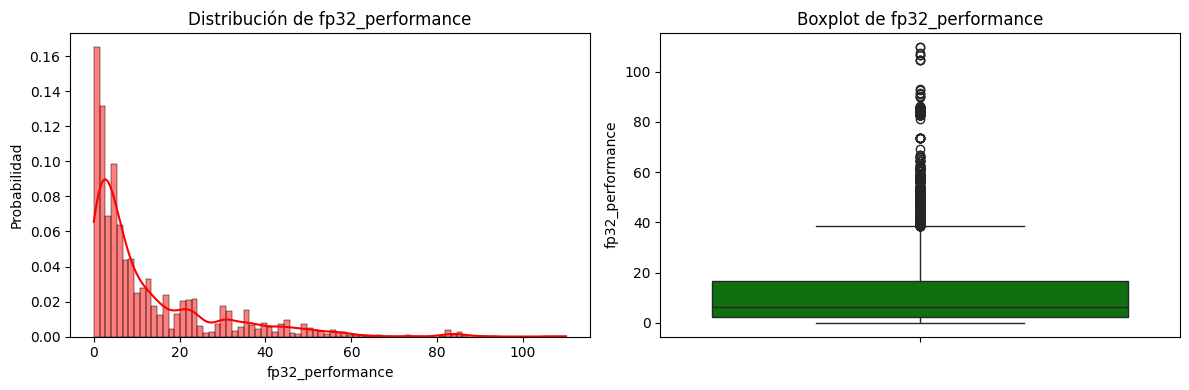

In [95]:
# Hicimos el histograma y el boxplot normal como se vio en clase
plt.figure(figsize=(12, 4))

# Histograma con KDE
ax1 = plt.subplot(1, 2, 1)
sns.histplot(
    data=df.dropna(subset=[TARGET]),
    x=TARGET,
    kde=True,
    color="red",
    stat="probability",
    ax=ax1
)
ax1.set_title(f"Distribución de {TARGET}")
ax1.set_xlabel(TARGET)
ax1.set_ylabel("Probabilidad")

# Boxplot
ax2 = plt.subplot(1, 2, 2)
sns.boxplot(data=df, y=TARGET, color="green", ax=ax2)
ax2.set_title(f"Boxplot de {TARGET}")
ax2.set_ylabel(TARGET)

plt.tight_layout()
plt.show()

### PDF y CDF empírica

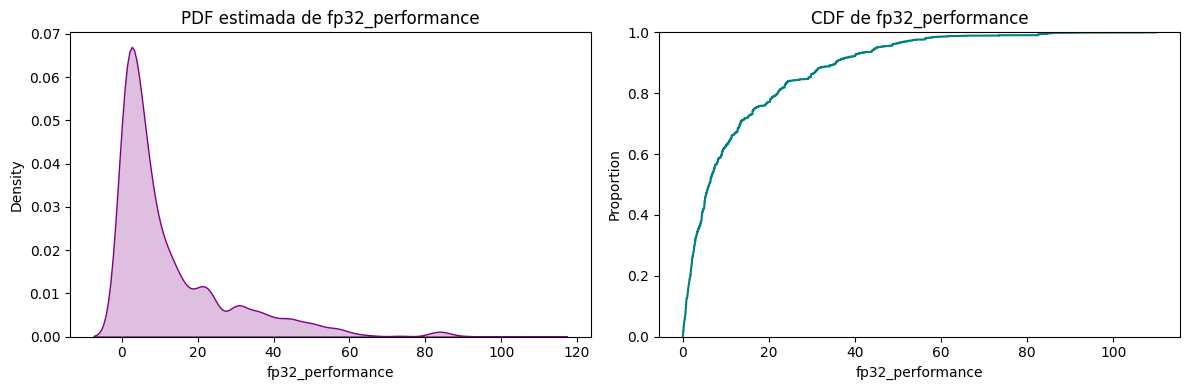

In [96]:
# lo mismo PDF y CDF que vimos en clase
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(df[TARGET].dropna(), fill=True, color="purple", ax=axes[0])
axes[0].set_title(f"PDF estimada de {TARGET}")

sns.ecdfplot(df[TARGET].dropna(), color="teal", ax=axes[1])
axes[1].set_title(f"CDF de {TARGET}")

plt.tight_layout()
plt.show()

### Estadísticas clave del target

In [97]:
# para concer los datos mas especificos los sacamos a mano
# sacamos la mediana, el primer y tercer cuartil para poder sacar la cajita
mediana = df[TARGET].median()
Q1 = df[TARGET].quantile(0.25)
Q3 = df[TARGET].quantile(0.75)
IQR = Q3 - Q1

print(f"Mediana: {mediana:.2f} TFLOPS")
print(f"Q1: {Q1:.2f} | Q3: {Q3:.2f} | IQR: {IQR:.2f}")

# Miramos los cortes de las clases
p50 = df[TARGET].quantile(0.50)
p85 = df[TARGET].quantile(0.85)

print(f"\nSegmentación:")
print(f"  Clase Bajo  (≤ p50)      : {p50:.2f} TFLOPS")
print(f"  Clase Medio (p50 – p85)  : {p50:.2f} – {p85:.2f} TFLOPS")
print(f"  Clase Alto  (> p85)      : {p85:.2f} TFLOPS")

Mediana: 6.17 TFLOPS
Q1: 2.14 | Q3: 16.66 | IQR: 14.52

Segmentación:
  Clase Bajo  (≤ p50)      : 6.17 TFLOPS
  Clase Medio (p50 – p85)  : 6.17 – 29.15 TFLOPS
  Clase Alto  (> p85)      : 29.15 TFLOPS


### Interpretación


Observaciones:
- La distribución de `fp32_performance` es **asimétrica positiva**
  (sesgo hacia la derecha): la mayoría de GPUs se concentran en valores
  bajos (0–20 TFLOPS (un TFLOP es cuántos billones de cálculos decimales puede hacer la GPU por segundo) ) y una cola larga se extiende hacia GPUs de gama alta.
- Hay una **cola derecha pronunciada** con outliers por encima de 60 TFLOPS
- La CDF confirma esto: aproximadamente el 80% de las GPUs están por debajo
  de ~20 TFLOPS.
- Implicación para el modelo: conviene probar transformaciones
  (log, sqrt) o modelos robustos a la asimetría (fuentes deepseek xd).

## 6. Análisis de outliers

### Boxplots por feature

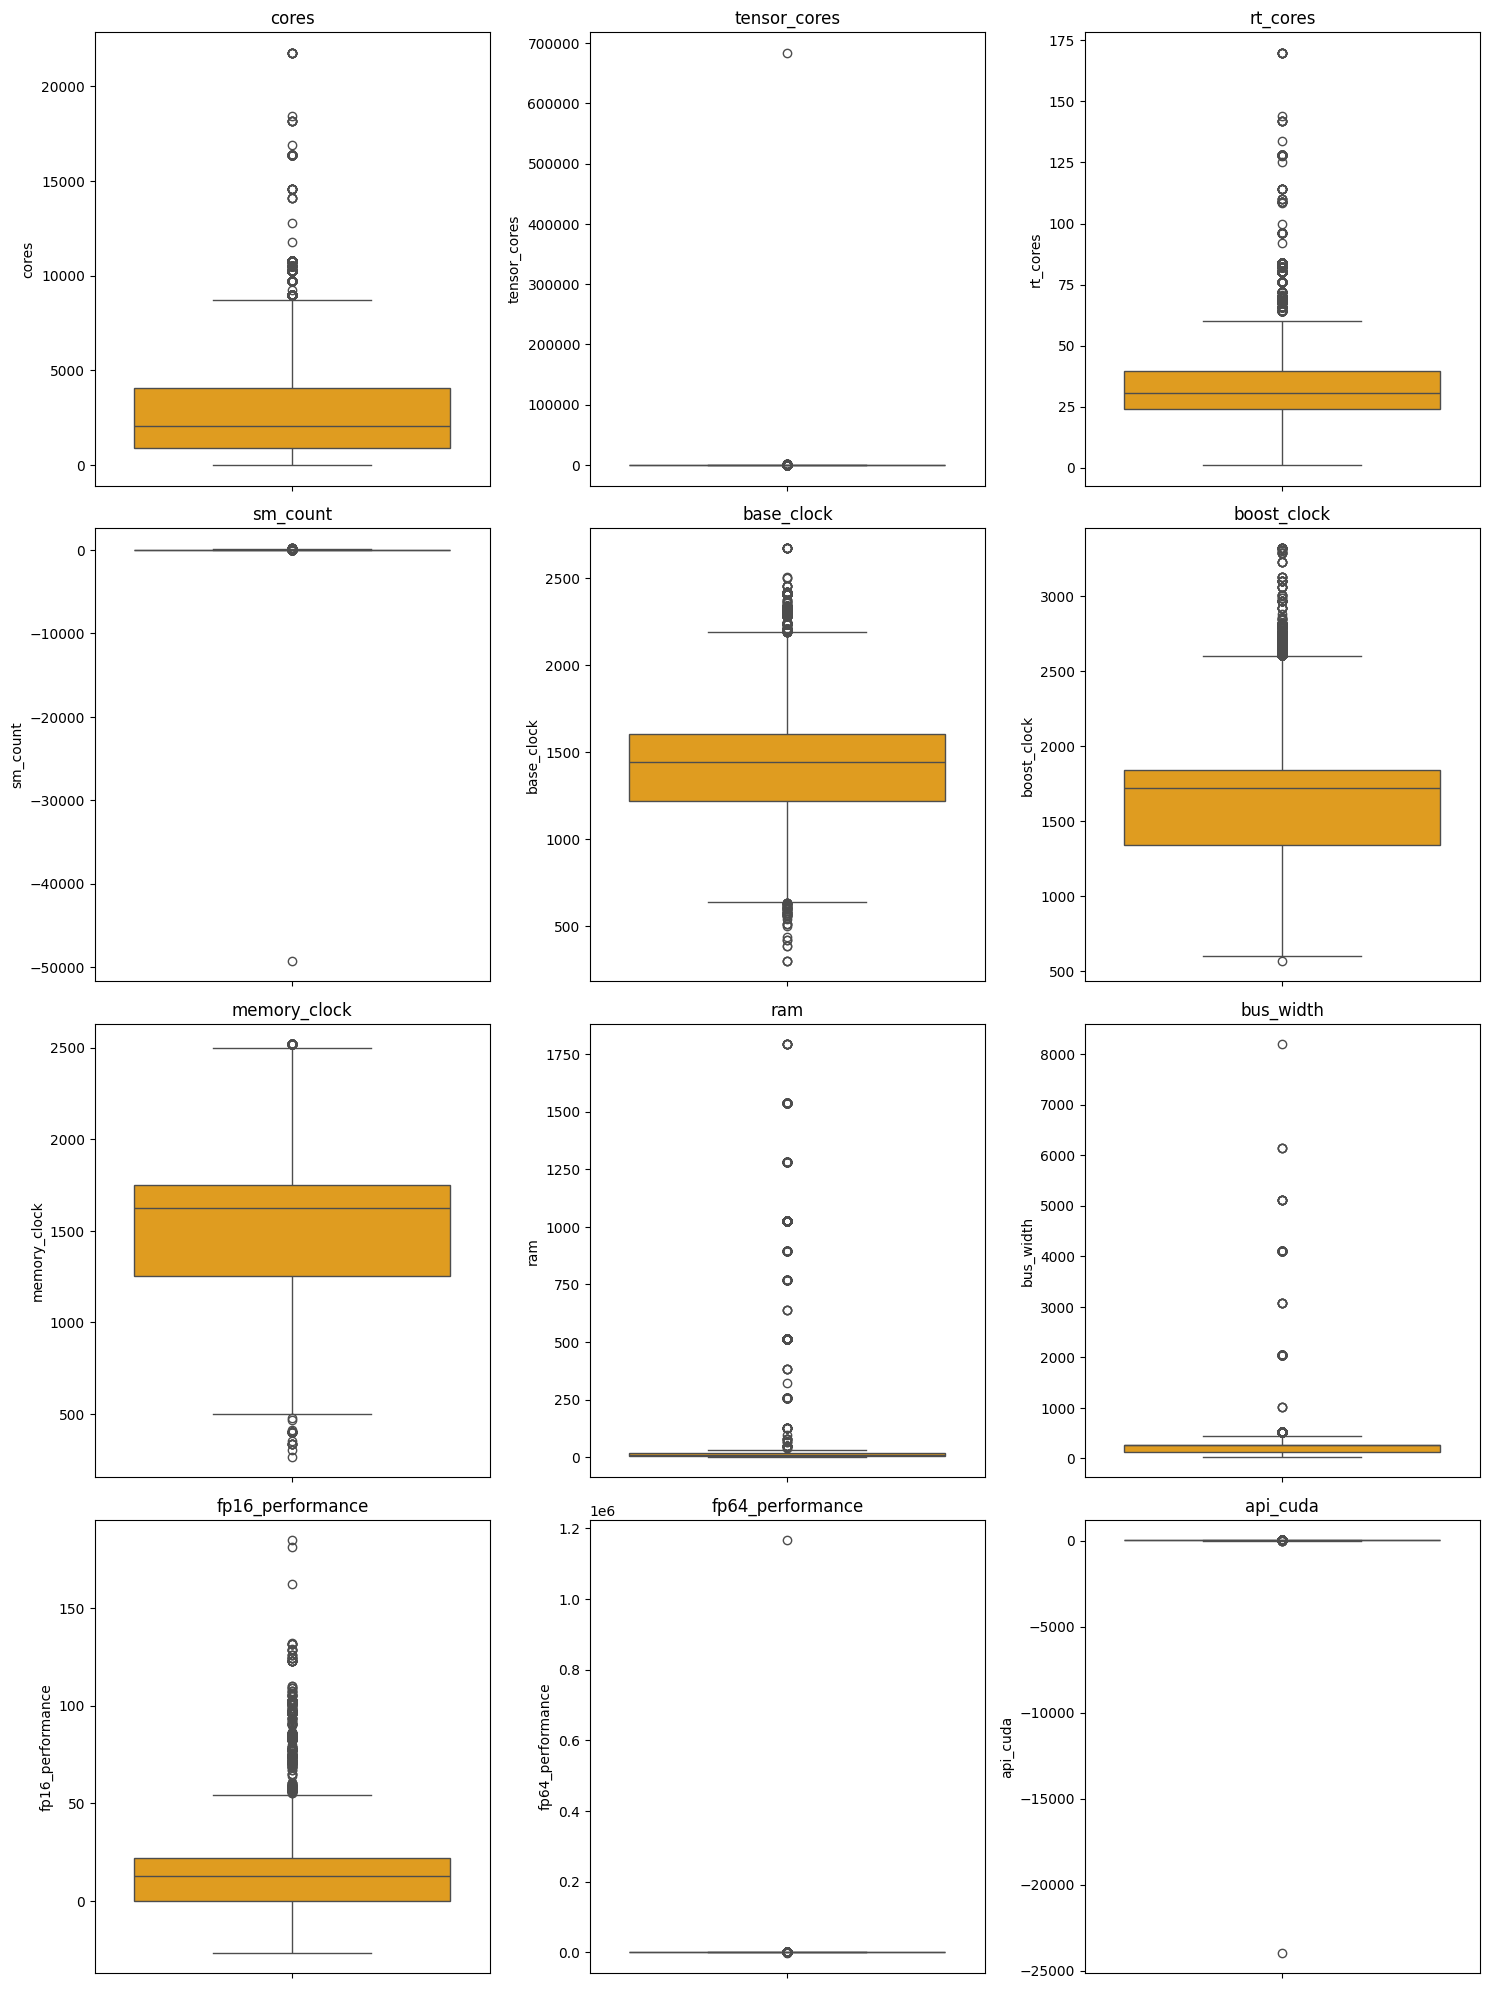

In [98]:
# creamos la lista de las variables numericas y como ya habiamos visto que todas
# era numericas simplemente sacamos las que no necesitamos
num_features = [c for c in df.columns if c not in ["id", "gpi_value", TARGET]]

# es una herramienta sorpresa que nos ayudara mas tarde
num_rows = (len(num_features) + 2) // 3 # Calcula cuántas filas de gráficos necesitamos si vemos 3 gráficos por fila

plt.figure(figsize=(15, 5 * num_rows)) # aca usamos el num_rows

# hacemos el boxplot por cada columna en la posicion que indique (i + 1)
# y le ponemos de titulo para que sea mas facil el nombre de la columna misma
for i, col in enumerate(num_features):
    ax = plt.subplot(num_rows, 3, i + 1)
    sns.boxplot(y=df[col], ax=ax, color="orange")
    ax.set_title(col)

plt.tight_layout()
plt.show()

### Histograma por feature

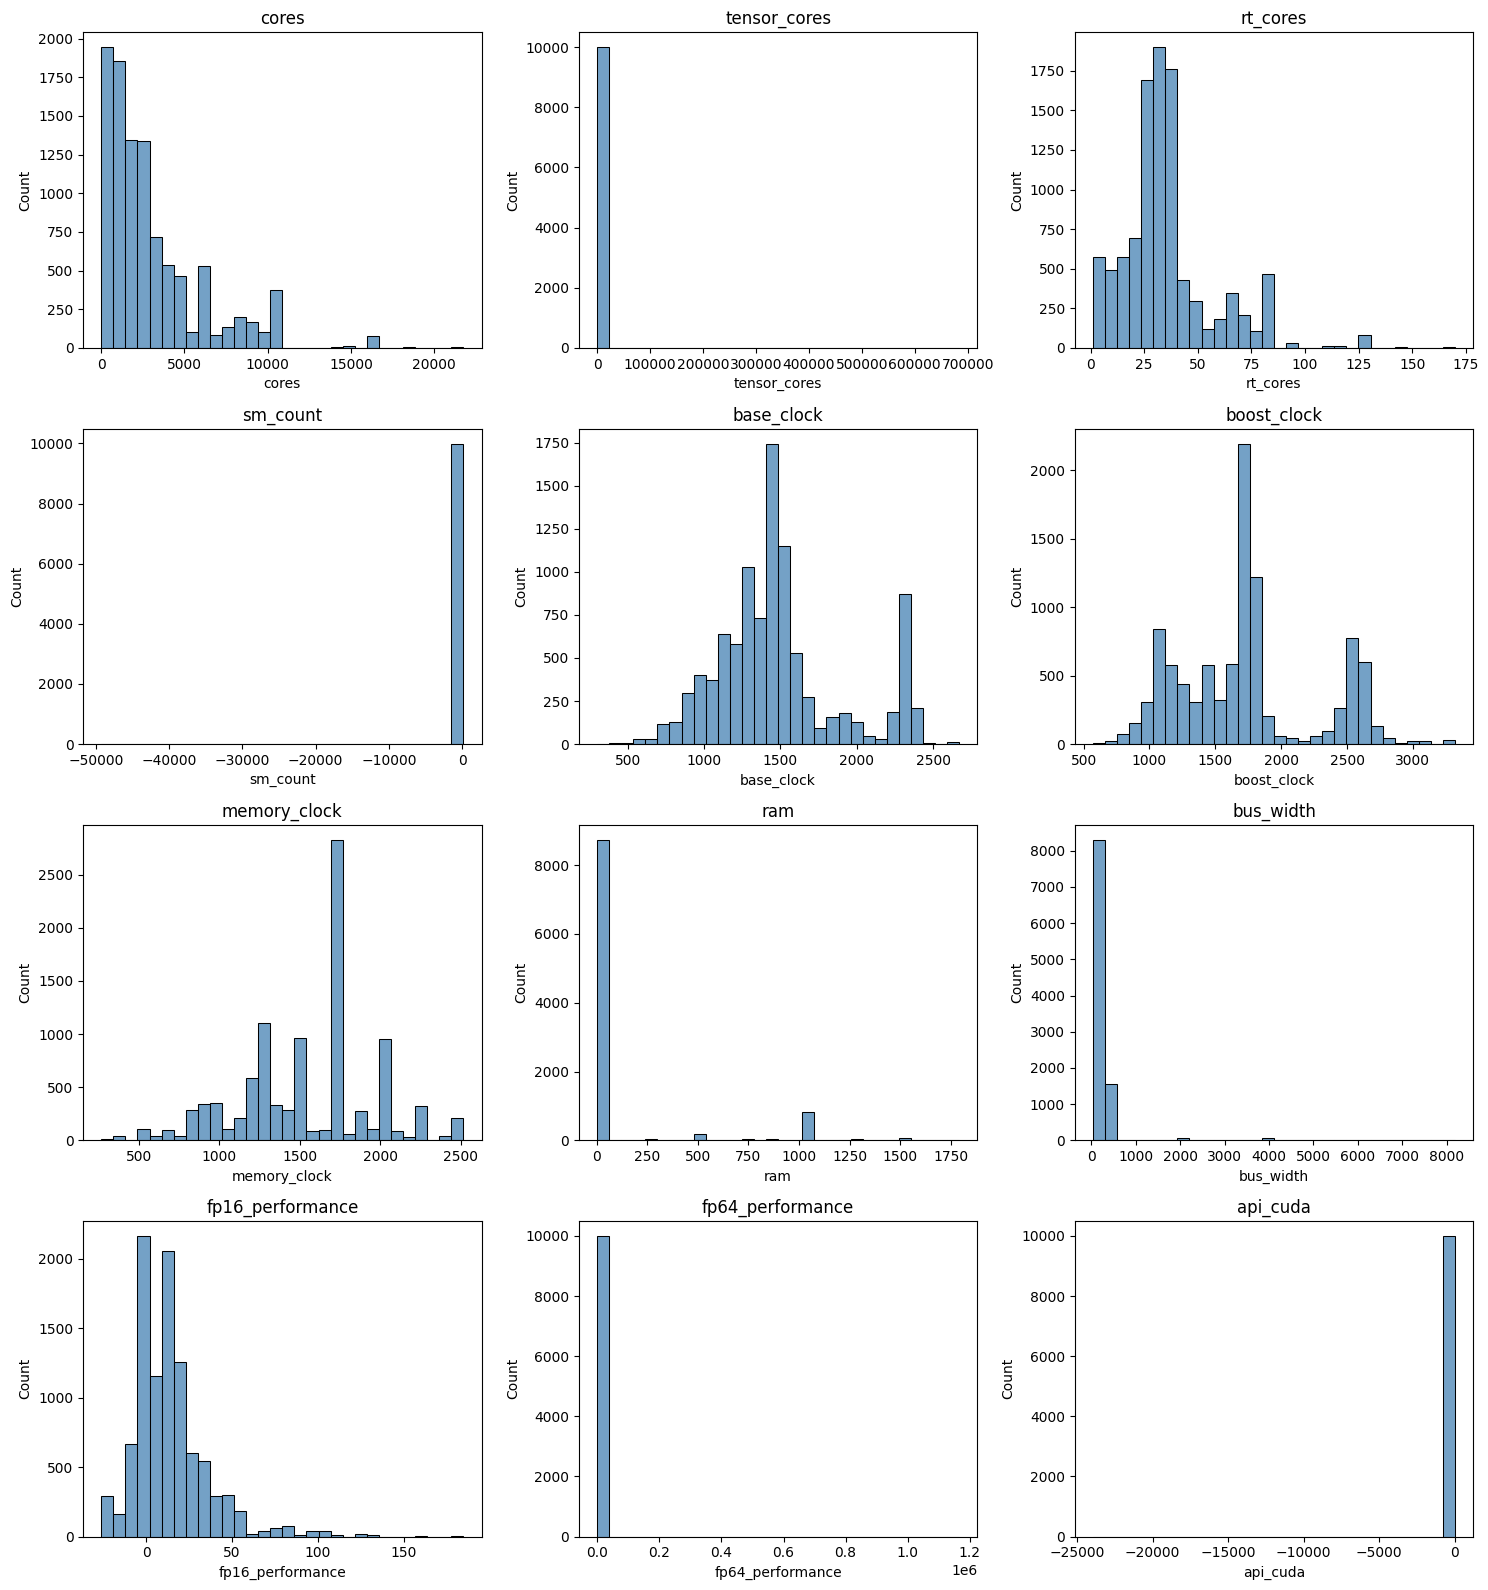

In [99]:
# reutilizamos num_features (ya excluye id, gpi_value y el target)
num_rows = (len(num_features) + 2) // 3  # 3 histogramas por fila

plt.figure(figsize=(15, 4 * num_rows))

# por cada feature dibujamos su histograma con KDE
# para ver de un vistazo la forma de la distribución (simetría, sesgo, cola)
for i, col in enumerate(num_features):
    ax = plt.subplot(num_rows, 3, i + 1)
    sns.histplot(data=df, x=col, kde=False, ax=ax, color="steelblue", bins=30)
    ax.set_title(col)

plt.tight_layout()
plt.show()

### Reporte IQR

In [100]:
# Analizamos outliers + estadísticas clave por feature
outlier_report = {}

for col in num_features:
    # Percentiles y rango intercuartílico
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1

    # Bigotes (límites de Tukey)
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

    # Contamos outliers y guardamos TODO junto
    outlier_report[col] = {
        "mediana": df[col].median(),
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "lower": lower,
        "upper": upper,
        "n_outliers": ((df[col] < lower) | (df[col] > upper)).sum()
    }

# Lo convertimos en DataFrame y ordenamos por cantidad de outliers
reporte = pd.DataFrame(outlier_report).T
reporte = reporte.sort_values("n_outliers", ascending=False)
reporte

,mediana,Q1,Q3,IQR,lower,upper,n_outliers
sm_count,30.012,24.000,39.221,15.221,1.168,62.053,1365.000
base_clock,1440.000,1216.000,1605.000,389.000,632.500,2188.500,1346.000
ram,8.000,4.000,16.000,12.000,-14.000,34.000,1278.000
rt_cores,30.682,24.148,39.596,15.448,0.975,62.768,1277.000
fp64_performance,0.267,0.134,0.563,0.429,-0.509,1.206,1063.000
cores,2048.000,896.000,4096.000,3200.000,-3904.000,8896.000,751.000
boost_clock,1719.943,1340.000,1845.000,505.000,582.500,2602.500,709.000
fp16_performance,12.780,0.101,22.060,21.959,-32.837,54.998,410.000
tensor_cores,259.718,175.390,320.000,144.610,-41.524,536.914,334.000
bus_width,256.000,128.000,256.000,128.000,-64.000,448.000,309.000


### Decisión

**No eliminamos outliers.** En este dataset representan GPUs de gama alta
legítimas, no errores de medición. Eliminarlos
sesgaría el modelo hacia hardware de gama media y le impediría aprender
a predecir rendimiento alto, que es justo el caso de uso más valioso.

## 7. Análisis de correlación

### Matriz de correlacion

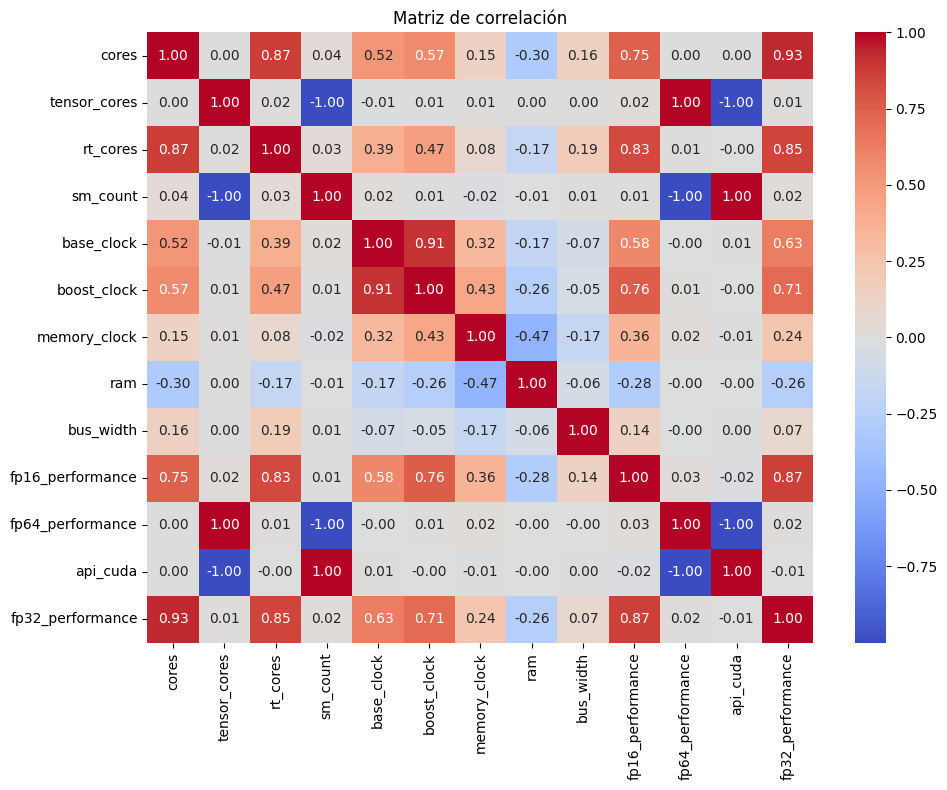

In [101]:
# Hacemos la matriz como lo que vimos en clase normal
plt.figure(figsize=(10, 8))

num_features_sin_target = [c for c in num_features if c != TARGET]
corr = df[num_features_sin_target + [TARGET]].corr()

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

### Ranking con el target

In [102]:
# Para verlo mas facil hacemos la correlacion con el Target del que mas relacion tiene al que menos
corr_target = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
print(f"Correlación con {TARGET}")
print(corr_target)

Correlación con fp32_performance
cores               0.935
fp16_performance    0.866
rt_cores            0.850
boost_clock         0.707
base_clock          0.627
ram                -0.258
memory_clock        0.237
bus_width           0.070
sm_count            0.022
fp64_performance    0.015
tensor_cores        0.015
api_cuda           -0.007
Name: fp32_performance, dtype: float64


### Interpretacion

**Correlación fuerte con el target:**
- `cores` (0.93), `fp16_performance` (0.87), `rt_cores` (0.85)

**Correlación media:**
- `boost_clock` (0.71), `base_clock` (0.63)

**Correlación débil o nula:**
- `sm_count` (0.02), `fp64_performance` (0.02), `tensor_cores` (0.01),
  `api_cuda` (−0.01), `bus_width` (0.07)

**Multicolinealidad detectada:**
- `cores` ↔ `rt_cores`, `cores` ↔ `fp16_performance`, `base_clock` ↔ `boost_clock`
  → conviene quedarse con una de cada par en la fase de feature engineering.

## 8. Conclusiones EDA

### Interpretación
- Correlación fuerte con el target: cores (0.93), fp16_performance (0.87), rt_cores (0.85).
- Correlación media: boost_clock (0.71), base_clock (0.63).
- Correlación débil: sm_count (0.02), fp64_performance (0.02), tensor_cores (0.01), api_cuda (−0.01), bus_width (0.07).

### Multicolinealidad
- cores ↔ rt_cores, cores ↔ fp16_performance, base_clock ↔ boost_clock.
- Implicación: Naive Bayes asume independencia, así que esto es una limitación.

### Distribución del target
- Se discretizó performance index en bajo (≤ p50, 50%), medio (p50–p85, 35%), alto (> p85, 15%).
- Justificación: refleja la pirámide real del mercado de GPUs (Steam Hardware Survey 2024).
- Clases desbalanceadas → usar stratify + class_weight + métricas macro.

### Outliers
- NO se eliminan: los valores extremos corresponden a GPUs de gama alta, que son la clase de interés.

##9. Analisis clasificador

### PREPARACION DEL TARGET BINARIO

In [103]:
p50 = df[TARGET].quantile(0.50)
df["target_bin"] = (df[TARGET] > p50).astype(int)   # 0 = bajo, 1 = alto

X = df.drop(columns=["id", "gpi_value", TARGET, "target_bin"])
y = df["target_bin"]

X_tmp, X_test, y_tmp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=42
)

resultados = []

# helper para no repetir el dict en cada loop
def evaluar(nombre, hp_str, modelo):
    modelo.fit(X_train, y_train)
    y_pred_tr = modelo.predict(X_train)
    y_pred_va = modelo.predict(X_val)

    f1_tr = f1_score(y_train, y_pred_tr)
    f1_va = f1_score(y_val,   y_pred_va)

    resultados.append({
        "Modelo":         nombre,
        "Hiperparámetro": hp_str,
        "Train_F1":       f1_tr,
        "Val_F1":         f1_va,
        "Gap":            f1_tr - f1_va,
        "Accuracy":       accuracy_score(y_val, y_pred_va),
        "Precision":      precision_score(y_val, y_pred_va, zero_division=0),
        "Recall":         recall_score(y_val, y_pred_va, zero_division=0),
    })
    return f1_va

mejores = {}

### GNB

In [104]:
mejor_f1, mejor_vs = -1, None
for v in [1e-10, 1e-9, 1e-8, 1e-7, 1e-6]:
    m = make_pipeline(StandardScaler(), GaussianNB(var_smoothing=v))
    f1 = evaluar("GNB", f"var_smoothing={v}", m)
    if f1 > mejor_f1:
        mejor_f1, mejor_vs = f1, v
mejores["GNB"] = {"var_smoothing": mejor_vs}
print(f"GNB -> mejor var_smoothing={mejor_vs} (Val F1={mejor_f1:.5f})")

GNB -> mejor var_smoothing=1e-10 (Val F1=0.89306)


### DECISION TREE

In [105]:
# Paso 1: max_depth

mejor_f1, mejor_depth = -1, None
for d in [1, 3, 5, 10, 15]:
    m = DecisionTreeClassifier(max_depth=d, random_state=42)
    f1 = evaluar("DecisionTree", f"max_depth={d}", m)
    if f1 > mejor_f1:
        mejor_f1, mejor_depth = f1, d
print(f"DT paso 1 -> max_depth={mejor_depth} (Val F1={mejor_f1:.5f})")

# Paso 2: min_samples_split

mejor_f1, mejor_split = -1, None
for s in [2, 5, 10, 20]:
    m = DecisionTreeClassifier(max_depth=mejor_depth,
                               min_samples_split=s, random_state=42)
    f1 = evaluar("DecisionTree",
                 f"max_depth={mejor_depth}, min_samples_split={s}", m)
    if f1 > mejor_f1:
        mejor_f1, mejor_split = f1, s
print(f"DT paso 2 -> min_samples_split={mejor_split} (Val F1={mejor_f1:.5f})")

# Paso 3: min_samples_leaf

mejor_f1, mejor_leaf = -1, None
for l in [1, 2, 4]:
    m = DecisionTreeClassifier(max_depth=mejor_depth,
                               min_samples_split=mejor_split,
                               min_samples_leaf=l, random_state=42)
    f1 = evaluar("DecisionTree",
                 f"max_depth={mejor_depth}, min_samples_split={mejor_split}, min_samples_leaf={l}",
                 m)
    if f1 > mejor_f1:
        mejor_f1, mejor_leaf = f1, l
print(f"DT paso 3 -> min_samples_leaf={mejor_leaf} (Val F1={mejor_f1:.5f})")
mejores["DecisionTree"] = {"max_depth": mejor_depth,
                           "min_samples_split": mejor_split,
                           "min_samples_leaf":  mejor_leaf}


DT paso 1 -> max_depth=10 (Val F1=0.99799)
DT paso 2 -> min_samples_split=2 (Val F1=0.99799)
DT paso 3 -> min_samples_leaf=1 (Val F1=0.99799)


### RANDOM FOREST

In [106]:
# Paso 1: n_estimators
mejor_f1, mejor_n = -1, None
for n in [50, 100, 200, 300]:
    m = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1)
    f1 = evaluar("RandomForest", f"n_estimators={n}", m)
    if f1 > mejor_f1:
        mejor_f1, mejor_n = f1, n
print(f"RF paso 1 -> n_estimators={mejor_n} (Val F1={mejor_f1:.5f})")

# Paso 2: max_depth
mejor_f1, mejor_rf_depth = -1, None
for d in [3, 5, 10, None]:
    m = RandomForestClassifier(n_estimators=mejor_n, max_depth=d,
                               random_state=42, n_jobs=-1)
    f1 = evaluar("RandomForest",
                 f"n_estimators={mejor_n}, max_depth={d}", m)
    if f1 > mejor_f1:
        mejor_f1, mejor_rf_depth = f1, d
print(f"RF paso 2 -> max_depth={mejor_rf_depth} (Val F1={mejor_f1:.5f})")

# Paso 3: min_samples_leaf
mejor_f1, mejor_rf_leaf = -1, None
for l in [1, 2, 4]:
    m = RandomForestClassifier(n_estimators=mejor_n, max_depth=mejor_rf_depth,
                               min_samples_leaf=l, random_state=42, n_jobs=-1)
    f1 = evaluar("RandomForest",
                 f"n_estimators={mejor_n}, max_depth={mejor_rf_depth}, min_samples_leaf={l}",
                 m)
    if f1 > mejor_f1:
        mejor_f1, mejor_rf_leaf = f1, l
print(f"RF paso 3 -> min_samples_leaf={mejor_rf_leaf} (Val F1={mejor_f1:.5f})")
mejores["RandomForest"] = {"n_estimators":     mejor_n,
                           "max_depth":        mejor_rf_depth,
                           "min_samples_leaf": mejor_rf_leaf}

RF paso 1 -> n_estimators=50 (Val F1=0.99950)
RF paso 2 -> max_depth=10 (Val F1=0.99950)
RF paso 3 -> min_samples_leaf=1 (Val F1=0.99950)


### SVM

In [107]:
# Paso 1: kernel
mejor_f1, mejor_kernel = -1, None
for k in ["linear", "rbf"]:
    m = make_pipeline(StandardScaler(), SVC(kernel=k, C=1, gamma="scale"))
    f1 = evaluar("SVM", f"kernel={k}", m)
    if f1 > mejor_f1:
        mejor_f1, mejor_kernel = f1, k
print(f"SVM paso 1 -> kernel={mejor_kernel} (Val F1={mejor_f1:.5f})")

# Paso 2: C  (kernel ya fijo)
mejor_f1, mejor_C = -1, None
for C in [0.1, 1, 10, 100]:
    m = make_pipeline(StandardScaler(),
                      SVC(kernel=mejor_kernel, C=C, gamma="scale"))
    f1 = evaluar("SVM", f"kernel={mejor_kernel}, C={C}", m)
    if f1 > mejor_f1:
        mejor_f1, mejor_C = f1, C
print(f"SVM paso 2 -> C={mejor_C} (Val F1={mejor_f1:.5f})")

# Paso 3: gamma  (solo si el kernel ganador es RBF)
if mejor_kernel == "rbf":
    mejor_f1, mejor_gamma = -1, None
    for g in ["scale", 0.01, 0.1, 1]:
        m = make_pipeline(StandardScaler(),
                          SVC(kernel="rbf", C=mejor_C, gamma=g))
        f1 = evaluar("SVM",
                     f"kernel=rbf, C={mejor_C}, gamma={g}", m)
        if f1 > mejor_f1:
            mejor_f1, mejor_gamma = f1, g
    print(f"SVM paso 3 -> gamma={mejor_gamma} (Val F1={mejor_f1:.5f})")
    mejores["SVM"] = {"kernel": "rbf", "C": mejor_C, "gamma": mejor_gamma}
else:
    print("SVM paso 3 -> saltado (kernel=linear no usa gamma)")
    mejores["SVM"] = {"kernel": "linear", "C": mejor_C}

SVM paso 1 -> kernel=rbf (Val F1=0.99291)
SVM paso 2 -> C=1 (Val F1=0.99291)
SVM paso 3 -> gamma=scale (Val F1=0.99291)


### RESULTADOS


In [108]:
df_resultados = pd.DataFrame(resultados)
pd.options.display.float_format = "{:.5f}".format

print("\n=== Todos los intentos (ordenados por Val_F1) ===")
display(df_resultados.sort_values("Val_F1", ascending=False).reset_index(drop=True))

# filtrar configuraciones con overfitting razonable (gap < 0.10)
df_limpio = df_resultados[df_resultados["Gap"] < 0.10].copy()

mejor_por_familia = (
    df_limpio
    .loc[df_limpio.groupby("Modelo")["Val_F1"].idxmax()]
    .sort_values("Val_F1", ascending=False)
    .reset_index(drop=True)
)
print("\n=== Mejor de cada familia (gap < 0.10) ===")
display(mejor_por_familia)


=== Todos los intentos (ordenados por Val_F1) ===


,Modelo,Hiperparámetro,Train_F1,Val_F1,Gap,Accuracy,Precision,Recall
0,RandomForest,"n_estimators=50, max_depth=10, min_samples_leaf=1",1.00000,0.99950,0.00050,0.99950,1.00000,0.99899
1,RandomForest,"n_estimators=50, max_depth=10, min_samples_leaf=2",1.00000,0.99950,0.00050,0.99950,1.00000,0.99899
2,RandomForest,n_estimators=50,1.00000,0.99950,0.00050,0.99950,1.00000,0.99899
3,RandomForest,n_estimators=300,1.00000,0.99950,0.00050,0.99950,1.00000,0.99899
4,RandomForest,n_estimators=200,1.00000,0.99950,0.00050,0.99950,1.00000,0.99899
5,RandomForest,n_estimators=100,1.00000,0.99950,0.00050,0.99950,1.00000,0.99899
6,RandomForest,"n_estimators=50, max_depth=None",1.00000,0.99950,0.00050,0.99950,1.00000,0.99899
7,RandomForest,"n_estimators=50, max_depth=10",1.00000,0.99950,0.00050,0.99950,1.00000,0.99899
8,DecisionTree,max_depth=10,0.99966,0.99799,0.00168,0.99800,0.99799,0.99799
9,DecisionTree,"max_depth=10, min_samples_split=2",0.99966,0.99799,0.00168,0.99800,0.99799,0.99799



=== Mejor de cada familia (gap < 0.10) ===


,Modelo,Hiperparámetro,Train_F1,Val_F1,Gap,Accuracy,Precision,Recall
0,RandomForest,n_estimators=50,1.00000,0.99950,0.00050,0.99950,1.00000,0.99899
1,DecisionTree,max_depth=10,0.99966,0.99799,0.00168,0.99800,0.99799,0.99799
2,SVM,kernel=rbf,0.99140,0.99291,-0.00151,0.99300,1.00000,0.98592
3,GNB,var_smoothing=1e-10,0.90489,0.89306,0.01183,0.89745,0.92741,0.86117



=== Top 2 para la fase multiclase ===


,Modelo,Hiperparámetro,Val_F1,Recall,Accuracy
0,RandomForest,n_estimators=50,0.99950,0.99899,0.99950
1,DecisionTree,max_depth=10,0.99799,0.99799,0.99800


### REENTRENAMIENTO DE LOS 2 GANADORES

In [109]:
top2 = mejor_por_familia.head(2)

def construir(nombre, hp):
    if nombre == "GNB":
        return make_pipeline(StandardScaler(), GaussianNB(**hp))
    if nombre == "DecisionTree":
        return DecisionTreeClassifier(random_state=42, **hp)
    if nombre == "RandomForest":
        return RandomForestClassifier(random_state=42, n_jobs=-1, **hp)
    if nombre == "SVM":
        return make_pipeline(StandardScaler(), SVC(**hp))
    raise ValueError(nombre)

X_trainval = pd.concat([X_train, X_val])
y_trainval = pd.concat([y_train, y_val])

print("\n=== Evaluación final en TEST (solo una vez) ===")
for _, row in top2.iterrows():
    modelo = construir(row["Modelo"], mejores[row["Modelo"]])
    modelo.fit(X_trainval, y_trainval)
    y_pred = modelo.predict(X_test)
    print(f"\n--- {row["Modelo"]} | {row["Hiperparámetro"]} ---")
    print(classification_report(y_test, y_pred, digits=3))


=== Evaluación final en TEST (solo una vez) ===

--- RandomForest | n_estimators=50 ---
              precision    recall  f1-score   support

           0      0.996     1.000     0.998      1005
           1      1.000     0.996     0.998       994

    accuracy                          0.998      1999
   macro avg      0.998     0.998     0.998      1999
weighted avg      0.998     0.998     0.998      1999


--- DecisionTree | max_depth=10 ---
              precision    recall  f1-score   support

           0      0.995     1.000     0.998      1005
           1      1.000     0.995     0.997       994

    accuracy                          0.997      1999
   macro avg      0.998     0.997     0.997      1999
weighted avg      0.998     0.997     0.997      1999

